In [1]:
import sys
print(sys.executable)

C:\Users\MAYELE\AppData\Local\anaconda3\envs\segmentation\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement
df = pd.read_csv("data/Mall_Customers.csv")

# Nettoyage des noms de colonnes (espaces en trop, ex. 'Education ')
df.columns = df.columns.str.strip()

print("Dimensions :", df.shape)
print("\nColonnes :", df.columns.tolist())
display(df.head())

print("\n--- Infos ---")
df.info()

print("\n--- Statistiques numériques ---")
display(df.describe())

print("\n--- Valeurs manquantes ---")
print(df.isna().sum())

print("\nDoublons :", df.duplicated().sum())

print("\n--- Variables catégorielles ---")
for col in ["Gender", "Education", "Marital Status"]:
    print(col, ":", df[col].value_counts().to_dict())

Dimensions : (200, 7)

Colonnes : ['CustomerID', 'Gender', 'Age', 'Education', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40



--- Infos ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Education               200 non-null    str  
 4   Marital Status          200 non-null    str  
 5   Annual Income (k$)      200 non-null    int64
 6   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(3)
memory usage: 14.3 KB

--- Statistiques numériques ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



--- Valeurs manquantes ---
CustomerID                0
Gender                    0
Age                       0
Education                 0
Marital Status            0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Doublons : 0

--- Variables catégorielles ---
Gender : {'F': 112, 'M': 88}
Education : {'Graduate': 67, 'High School': 40, 'Uneducated': 31, 'Unknown': 26, 'College': 17, 'Doctorate': 11, 'Post-Graduate': 8}
Marital Status : {'Married': 112, 'Single': 61, 'Unknown': 15, 'Divorced': 12}


In [3]:
import os
print(os.getcwd())
print(os.listdir("."))
print(os.path.exists("data/Mall_Customers.csv"), os.path.exists("../data/Mall_Customers.csv"))

C:\Users\MAYELE\Documents\segmentation-customer
['.git', '.gitignore', '.idea', '.ipynb_checkpoints', 'app', 'data', 'models', 'notebooks', 'README.md', 'requirements.txt']
True False


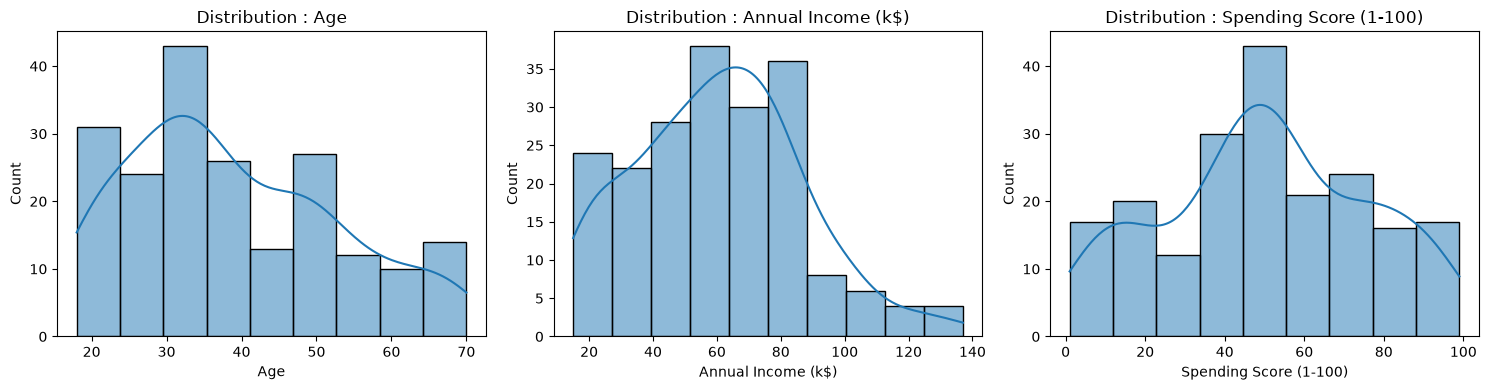

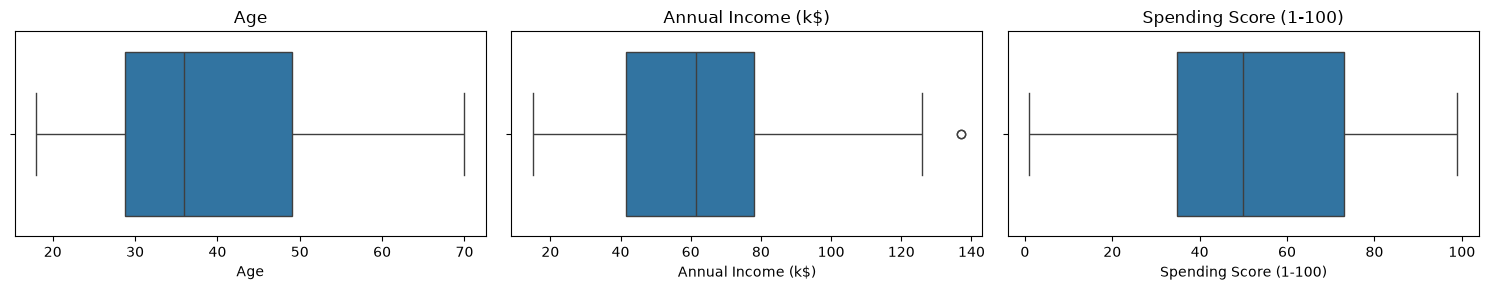

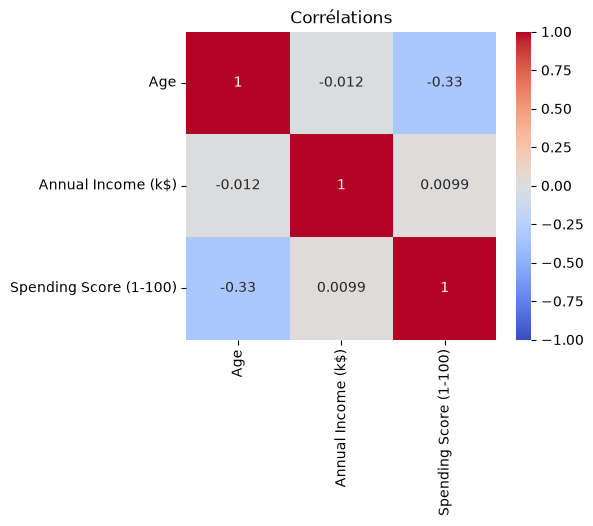

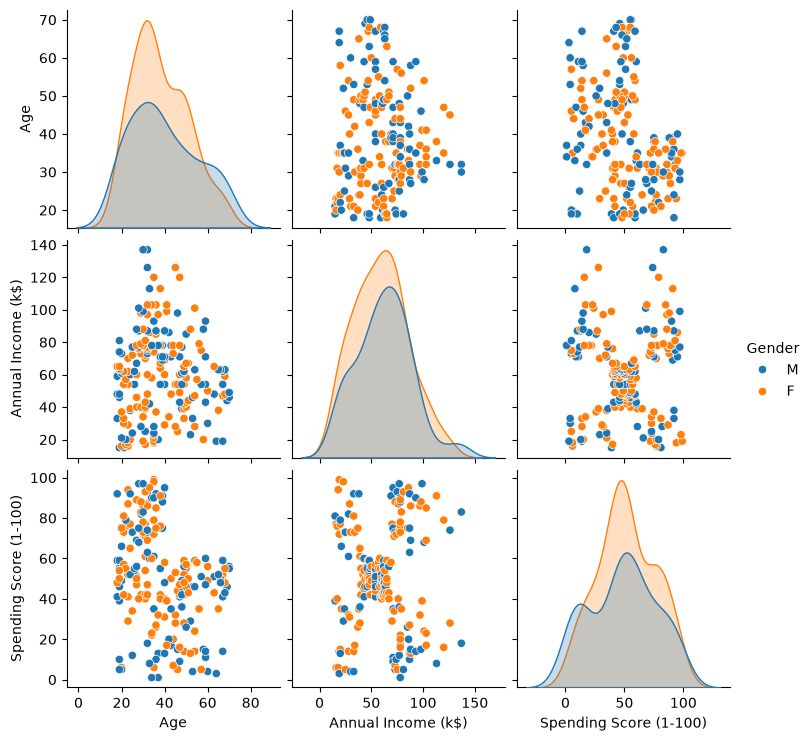

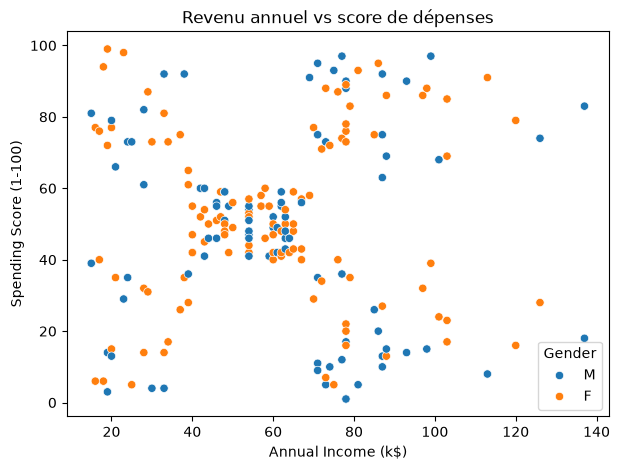

In [3]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

# 1. Distributions des variables numériques
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution : {col}")
plt.tight_layout()
plt.show()

# 2. Valeurs extrêmes
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3. Corrélations
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélations")
plt.show()

# 4. Relations entre variables, colorées par genre
sns.pairplot(df[num_cols + ["Gender"]], hue="Gender", diag_kind="kde")
plt.show()

# 5. Revenu vs score de dépenses (le graphique clé)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender")
plt.title("Revenu annuel vs score de dépenses")
plt.show()

In [4]:
from sklearn.preprocessing import StandardScaler

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features)

print("Avant mise à l'échelle :")
display(X.describe().loc[["mean", "std", "min", "max"]].round(2))

print("\nAprès mise à l'échelle :")
display(X_scaled.describe().loc[["mean", "std", "min", "max"]].round(2))

Avant mise à l'échelle :


,Age,Annual Income (k$),Spending Score (1-100)
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
max,70.00,137.00,99.00



Après mise à l'échelle :


,Age,Annual Income (k$),Spending Score (1-100)
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
max,2.24,2.92,1.89


,k,inertie,silhouette
0,2,389.4,0.335
1,3,295.2,0.358
2,4,205.2,0.404
3,5,168.2,0.417
4,6,133.9,0.428
5,7,117.0,0.417
6,8,103.9,0.408
7,9,93.1,0.418
8,10,82.4,0.407


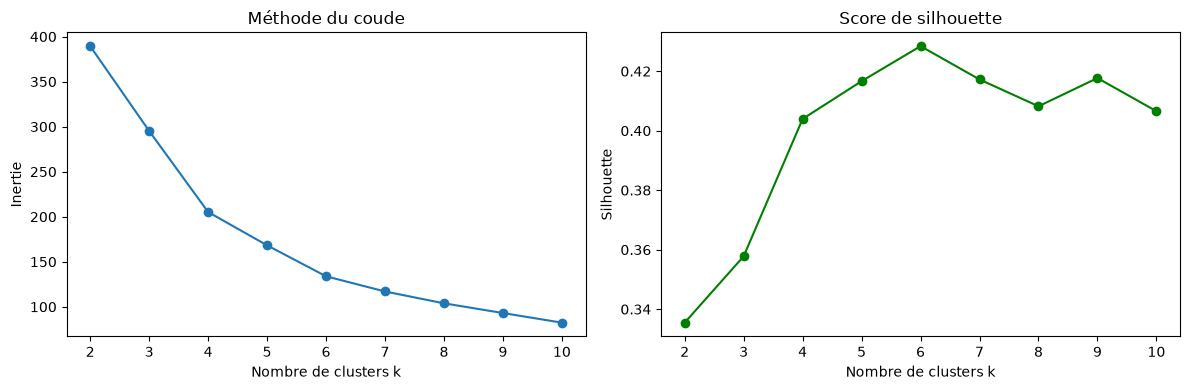

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

resultats = pd.DataFrame({
    "k": list(k_range),
    "inertie": np.round(inertias, 1),
    "silhouette": np.round(silhouettes, 3),
})
display(resultats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, inertias, marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("Nombre de clusters k")
axes[0].set_ylabel("Inertie")

axes[1].plot(k_range, silhouettes, marker="o", color="green")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters k")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

Silhouette : 0.428


,Age,Annual Income (k$),Spending Score (1-100),Effectif
0,56.3,54.3,49.1,45
1,26.8,57.1,48.1,39
2,41.9,88.9,17.0,33
3,32.7,86.5,82.1,39
4,25.0,25.3,77.6,23
5,45.5,26.3,19.4,21


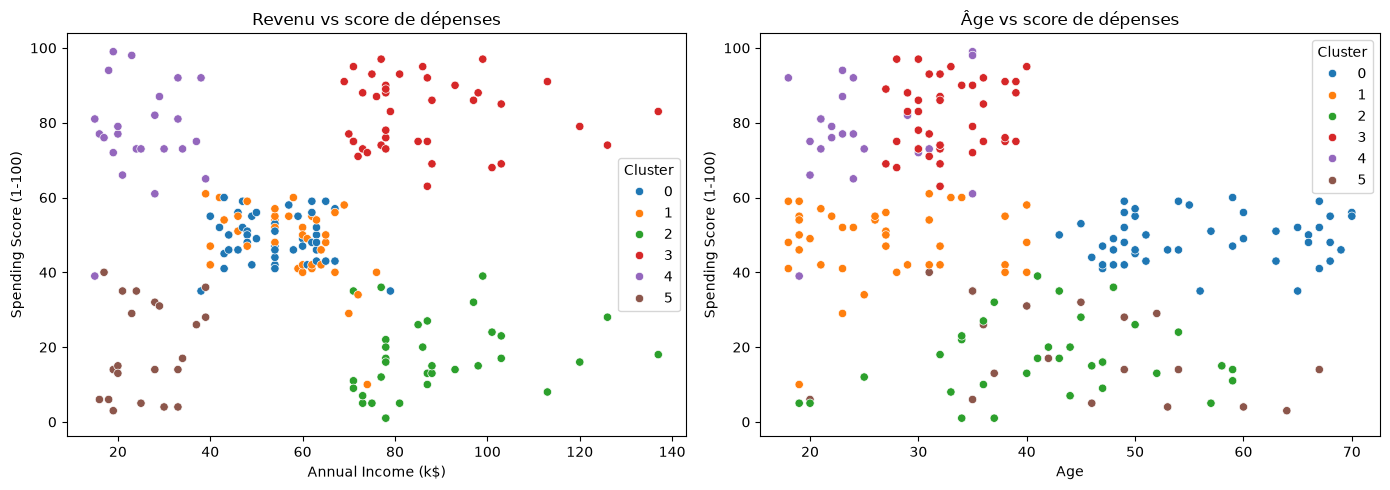

['models/scaler.joblib']

In [6]:
import joblib

K = 6  # on testera aussi 5

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Silhouette :", round(silhouette_score(X_scaled, df["Cluster"]), 3))

# Profil moyen de chaque cluster, en unités d'origine
centres = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
).round(1)
centres["Effectif"] = df["Cluster"].value_counts().sort_index().values
display(centres)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", ax=axes[0])
axes[0].set_title("Revenu vs score de dépenses")
sns.scatterplot(data=df, x="Age", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", ax=axes[1])
axes[1].set_title("Âge vs score de dépenses")
plt.tight_layout()
plt.show()

# Sauvegarde pour l'interface web
joblib.dump(kmeans, "models/kmeans.joblib")
joblib.dump(scaler, "models/scaler.joblib")

In [7]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=42)
labels5 = km5.fit_predict(X_scaled)

print("Silhouette k=5 :", round(silhouette_score(X_scaled, labels5), 3))

profil5 = pd.DataFrame(
    scaler.inverse_transform(km5.cluster_centers_),
    columns=features
).round(1)
profil5["Effectif"] = pd.Series(labels5).value_counts().sort_index().values
display(profil5)

Silhouette k=5 : 0.417


,Age,Annual Income (k$),Spending Score (1-100),Effectif
0,46.2,26.8,18.3,20
1,25.2,41.1,62.2,54
2,32.9,86.1,81.5,40
3,39.9,86.1,19.4,39
4,55.6,54.4,48.9,47
